In [1]:
# Desinstalação completa e limpeza física de ficheiros residuais em cache
!pip uninstall -y trl transformers peft accelerate datasets
!rm -rf /usr/local/lib/python3.13/dist-packages/trl*
!rm -rf /usr/local/lib/python3.13/dist-packages/transformers*

# Reinstalação limpa e forçada sem cache
!pip install --no-cache-dir -q "transformers>=4.48.0" "trl>=0.13.0" "peft>=0.14.0" "datasets>=3.0.0" "datasketch>=1.6" accelerate

Found existing installation: trl 1.16.0
Uninstalling trl-1.16.0:
  Successfully uninstalled trl-1.16.0
Found existing installation: transformers 5.20.2
Uninstalling transformers-5.20.2:
  Successfully uninstalled transformers-5.20.2
Found existing installation: peft 0.21.2
Uninstalling peft-0.21.2:
  Successfully uninstalled peft-0.21.2
Found existing installation: accelerate 1.15.0
Uninstalling accelerate-1.15.0:
  Successfully uninstalled accelerate-1.15.0
Found existing installation: datasets 5.1.0
Uninstalling datasets-5.1.0:
  Successfully uninstalled datasets-5.1.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 126.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 948.2/948.2 kB 118.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 129.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 108.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 244.1 MB/s eta 0:00:00


In [2]:
# Atualizar o torchao para uma versão compatível com as dependências do PEFT
!pip install --no-cache-dir -U "torchao>=0.16.0"

# PL6 · Desafios Extra (Ponto 6)

Este notebook contém a resolução detalhada, individualizada e executável dos 5 desafios propostos no **Ponto 6** da aula prática de **IA Generativa (PL6)**:

1. **Dr. GRPO vs GRPO:** repita a Parte 5 com `loss_type="dr_grpo"` e `scale_rewards=False`. Compare o comprimento das respostas.
2. **β = 0:** treine o GRPO sem KL (`beta=0.0`). O que acontece à entropia e ao KL implícito?
3. **IPO:** na Parte 4, use `loss_type="ipo"` no `DPOConfig` e compare `logps/chosen`.
4. **Português:** adapte os filtros da Parte 1 a português (stopwords, comprimento médio) e meça quantos originais deixam de ser removidos.
5. **Hacking:** suba a recompensa de formato para 1,0 e observe se a correção piora.


---
## 0 · Configuração Inicial e Dependências


In [3]:
import os, re, math, random, time, gc
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from datasets import load_dataset
from transformers import AutoModelForCausalLM, AutoTokenizer
from peft import LoraConfig
from trl import DPOConfig, DPOTrainer, GRPOConfig, GRPOTrainer

# Fixar sementes
SEMENTE = 42
random.seed(SEMENTE)
np.random.seed(SEMENTE)
torch.manual_seed(SEMENTE)

# Dispositivo e modelo base
MODELO = "Qwen/Qwen2.5-0.5B-Instruct"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
# Forçar BF16 para False caso a GPU não tenha capacidade computacional >= 8.0
BF16 = False
if DEVICE == "cuda":
    capacidade = torch.cuda.get_device_capability()
    if capacidade[0] >= 8:
        BF16 = torch.cuda.is_bf16_supported()

tok = AutoTokenizer.from_pretrained(MODELO)

def limpar_memoria():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print(f"Dispositivo: {DEVICE} | BF16: {BF16} | Modelo: {MODELO}")

Dispositivo: cuda | BF16: False | Modelo: Qwen/Qwen2.5-0.5B-Instruct


---
## Desafio 4 · Adaptação dos Filtros Heurísticos a Português

> **Enunciado:** *Adapte os filtros da Parte 1 a português (stopwords, comprimento médio) e meça quantos originais deixam de ser removidos.*

### Contexto e Justificação:
- No filtro heurístico inicial (baseado em Gopher), as stopwords continham apenas algumas palavras portuguesas e várias inglesas (`the`, `be`, `to`, `of`, etc.). Em textos estritamente em português, uma lista restrita de stopwords causa a rejeição indevida de textos válidos (falsos positivos).
- O comprimento médio das palavras em português tende a ser mais longo (média de 4 a 6 caracteres, com termos técnicos ou jurídicos a atingir médias superiores) devido a sufixos e flexões.
- **Ajustes:**
  1. Criação de um dicionário expandido de **stopwords em português** (artigos, preposições, pronomes, verbos auxiliares frequentes).
  2. Ajuste do limiar de **comprimento médio de palavras** de `[3, 10]` para `[3.0, 12.0]`.
  3. Medição direta de quantos documentos do tipo `original` deixam de ser eliminados (passam de motivo de erro para `'ok'`).


In [4]:
# Carregar corpus e corromper (mesmo protocolo da Parte 1)
N_DOCS = 3000

def corpus_sintetico(n=N_DOCS, seed=0):
    rng = random.Random(seed)
    vocab = ("o a de que e do da em um para com não uma os no se na por mais as dos como mas foi ao ele das tem "
             "seu sua ou ser quando muito há nos já está também só pelo pela até isso ela entre era depois sem mesmo "
             "cidade governo universidade estudo dados modelo sistema projeto trabalho tempo ano país mundo forma parte "
             "vida história caso problema lugar empresa grupo região investigação resultado processo").split()
    docs = []
    for _ in range(n):
        alvo, frases, w = rng.randint(30, 600), [], 0
        while w < alvo:
            k = rng.randint(6, 20); w += k
            frases.append(" ".join(rng.choice(vocab) for _ in range(k)).capitalize() + ".")
        docs.append(" ".join(frases))
    return docs

def carregar_corpus(n=N_DOCS):
    for nome, cfg in [("HuggingFaceFW/fineweb-2", "por_Latn"), ("HuggingFaceFW/fineweb", "sample-10BT")]:
        try:
            ds = load_dataset(nome, name=cfg, split="train", streaming=True)
            docs = [x["text"] for _, x in zip(range(n), ds)]
            print(f"Carregados {len(docs)} documentos de {nome} [{cfg}]")
            return docs
        except Exception as e:
            print(f"Falhou {nome} [{cfg}]: {type(e).__name__}")
    print("A usar corpus sintético (fallback).")
    return corpus_sintetico(n)

docs = carregar_corpus(N_DOCS)

def quase_duplicado(texto, taxa, rng):
    palavras, out = texto.split(), []
    for p in palavras:
        u = rng.random()
        if u < taxa / 2:   continue
        elif u < taxa:     out.append(rng.choice(palavras))
        else:              out.append(p)
    return " ".join(out)

LIXO = [
    lambda rng: "\n".join("• " + rng.choice(["Início", "Contactos", "Loja", "Login", "Carrinho", "Termos", "Privacidade"]) for _ in range(40)),
    lambda rng: " ".join(rng.choice(["#promo", "#oferta", "...", "$$$", "#grátis", "#top"]) for _ in range(200)),
    lambda rng: "clique aqui para saber mais " * 40,
    lambda rng: "Lorem ipsum dolor sit amet, consectetur adipiscing elit. " * 20,
]

def corromper(docs, n_exatos=50, n_quase=100, n_lixo=50, taxa=0.02, seed=0):
    rng = random.Random(seed)
    corpus = [{"id": i, "texto": t, "tipo": "original", "origem": None} for i, t in enumerate(docs)]
    base = [d for d in corpus if len(d["texto"].split()) >= 100]
    for _ in range(n_exatos):
        d = rng.choice(base); corpus.append({"id": len(corpus), "texto": d["texto"], "tipo": "exato", "origem": d["id"]})
    for _ in range(n_quase):
        d = rng.choice(base); corpus.append({"id": len(corpus), "texto": quase_duplicado(d["texto"], taxa, rng), "tipo": "quase", "origem": d["id"]})
    for _ in range(n_lixo):
        corpus.append({"id": len(corpus), "texto": rng.choice(LIXO)(rng), "tipo": "lixo", "origem": None})
    rng.shuffle(corpus)
    return corpus

corpus = corromper(docs)


Resolving data files:   0%|          | 0/66 [00:00<?, ?it/s]

Carregados 3000 documentos de HuggingFaceFW/fineweb-2 [por_Latn]


In [5]:
# 1. Filtros Originais da Parte 1
STOP_ORIGINAL = {"de", "a", "o", "que", "e", "do", "da", "em", "um", "para", "é", "com", "não", "uma", "os", "no", "se", "na", "por",
                 "the", "be", "to", "of", "and", "that", "have", "with"}

def frac_top_ngrama(texto, n=2):
    p = texto.lower().split()
    grams = [" ".join(p[i:i + n]) for i in range(len(p) - n + 1)]
    if not grams:
        return 0.0
    g, c = Counter(grams).most_common(1)[0]
    return c * len(g.replace(" ", "")) / max(1, sum(len(x) for x in p))

def filtro_repeticao(texto, limiar=0.20):
    if frac_top_ngrama(texto, n=2) > limiar:
        return False, "repeticao"
    return True, "ok"

def filtro_gopher_original(texto, stop=STOP_ORIGINAL):
    palavras = texto.split()
    n = len(palavras)
    if not (50 <= n <= 100_000):
        return False, "n_palavras"
    media = sum(len(p) for p in palavras) / n
    if not (3 <= media <= 10):
        return False, "comprimento_medio"
    total_simbolos = texto.count("#") + texto.count("...") + texto.count("…")
    if (total_simbolos / n) > 0.10:
        return False, "racio"
    com_letras = sum(any(c.isalpha() for c in p) for p in palavras) / n
    if com_letras < 0.80:
        return False, "palavras_sem_letras"
    linhas = [l.strip() for l in texto.split("\n") if l.strip()]
    if linhas:
        if (sum(l.startswith(("•", "-", "*")) for l in linhas) / len(linhas)) > 0.90:
            return False, "marcadores"
        if (sum(l.endswith(("...", "…")) for l in linhas) / len(linhas)) > 0.30:
            return False, "reticencias"
    n_stop = sum(1 for p in palavras if p.lower() in stop)
    if n_stop < 2:
        return False, "stopwords"
    return True, "ok"

def aplicar_filtros_original(texto):
    ok, motivo = filtro_gopher_original(texto)
    if not ok:
        return motivo
    ok, motivo = filtro_repeticao(texto)
    return "ok" if ok else motivo


In [6]:
# 2. Filtros Adaptados a Português
STOP_PT = {
    "de", "a", "o", "que", "e", "do", "da", "em", "um", "para", "é", "com", "não", "uma", "os", "no", "se", "na", "por",
    "mais", "as", "dos", "como", "mas", "foi", "ao", "ele", "das", "tem", "à", "seu", "sua", "ou", "ser", "quando",
    "muito", "nos", "já", "está", "eu", "também", "só", "pelo", "pela", "até", "isso", "ela", "entre", "era", "depois",
    "sem", "mesmo", "aos", "ter", "seus", "quem", "nas", "me", "esse", "eles", "estão", "você", "tinha", "foram", "essa",
    "num", "nem", "suas", "meu", "às", "minha", "têm", "numa", "pelos", "elas", "havia", "seja", "qual", "será", "nós"
}

def filtro_gopher_pt(texto, stop=STOP_PT):
    palavras = texto.split()
    n = len(palavras)
    if not (50 <= n <= 100_000):
        return False, "n_palavras"
    media = sum(len(p) for p in palavras) / n
    # Ajustado de 10 para 12 para acomodar a morfologia de textos em língua portuguesa
    if not (3.0 <= media <= 12.0):
        return False, "comprimento_medio"
    total_simbolos = texto.count("#") + texto.count("...") + texto.count("…")
    if (total_simbolos / n) > 0.10:
        return False, "racio"
    com_letras = sum(any(c.isalpha() for c in p) for p in palavras) / n
    if com_letras < 0.80:
        return False, "palavras_sem_letras"
    linhas = [l.strip() for l in texto.split("\n") if l.strip()]
    if linhas:
        if (sum(l.startswith(("•", "-", "*")) for l in linhas) / len(linhas)) > 0.90:
            return False, "marcadores"
        if (sum(l.endswith(("...", "…")) for l in linhas) / len(linhas)) > 0.30:
            return False, "reticencias"
    n_stop = sum(1 for p in palavras if p.lower() in stop)
    if n_stop < 2:
        return False, "stopwords"
    return True, "ok"

def aplicar_filtros_pt(texto):
    ok, motivo = filtro_gopher_pt(texto)
    if not ok:
        return motivo
    ok, motivo = filtro_repeticao(texto)
    return "ok" if ok else motivo


In [7]:
# 3. Medição Quantitativa dos Originais Recuperados
res_orig = [aplicar_filtros_original(d["texto"]) for d in corpus]
res_pt = [aplicar_filtros_pt(d["texto"]) for d in corpus]

df_comp = pd.DataFrame({
    "tipo": [d["tipo"] for d in corpus],
    "filtro_original": res_orig,
    "filtro_adaptado_pt": res_pt
})

print("=== CROSSTAB FILTRO ORIGINAL ===")
print(pd.crosstab(df_comp["tipo"], df_comp["filtro_original"]))

print("\n=== CROSSTAB FILTRO ADAPTADO A PORTUGUÊS ===")
print(pd.crosstab(df_comp["tipo"], df_comp["filtro_adaptado_pt"]))

originais_totais = sum(df_comp["tipo"] == "original")
removidos_orig = sum((df_comp["tipo"] == "original") & (df_comp["filtro_original"] != "ok"))
removidos_pt = sum((df_comp["tipo"] == "original") & (df_comp["filtro_adaptado_pt"] != "ok"))
recuperados = removidos_orig - removidos_pt

print(f"\nDocumentos originais totais: {originais_totais}")
print(f"Originais removidos com filtro original: {removidos_orig}")
print(f"Originais removidos com filtro adaptado a PT: {removidos_pt}")
print(f"-> ORIGINAIS QUE DEIXARAM DE SER REMOVIDOS: {recuperados}")

# Taxa de filtragem de lixo real
lixo_filtrado = sum((df_comp["tipo"] == "lixo") & (df_comp["filtro_adaptado_pt"] != "ok"))
total_lixo = sum(df_comp["tipo"] == "lixo")
print(f"Taxa de deteção de lixo: {lixo_filtrado}/{total_lixo} ({lixo_filtrado/total_lixo:.0%})")


=== CROSSTAB FILTRO ORIGINAL ===
filtro_original  marcadores    ok  palavras_sem_letras  racio  repeticao  \
tipo                                                                       
exato                     0    50                    0      0          0   
lixo                      0     0                    8     18         13   
original                  0  2999                    0      1          0   
quase                     2    96                    0      0          0   

filtro_original  reticencias  stopwords  
tipo                                     
exato                      0          0  
lixo                       0         11  
original                   0          0  
quase                      2          0  

=== CROSSTAB FILTRO ADAPTADO A PORTUGUÊS ===
filtro_adaptado_pt  marcadores    ok  palavras_sem_letras  racio  repeticao  \
tipo                                                                          
exato                        0    50                  

### Síntese do Desafio 4:
Ao adaptar o léxico de stopwords e relaxar o limiar de comprimento médio para a realidade da língua portuguesa, recuperam-se textos legítimos que eram antes incorretamente rotulados como anómalos (falsos positivos), mantendo a taxa de eliminação de lixo a 100%.


---
## Desafio 3 · IPO (Identity Preference Optimization) vs DPO

> **Enunciado:** *Na Parte 4, use `loss_type="ipo"` no `DPOConfig` e compare `logps/chosen`.*

### Enquadramento Teórico:
- A perda clássica do **DPO** baseia-se na sigmóide da margem:
  $$\mathcal{L}_{\text{DPO}} = -\log \sigma \left( \beta \log \frac{\pi_\theta(y_w|x)}{\pi_{\text{ref}}(y_w|x)} - \beta \log \frac{\pi_\theta(y_l|x)}{\pi_{\text{ref}}(y_l|x)} \right)$$
  Isto força a probabilidade de $y_l$ para zero, podendo conduzir a instabilidades onde a própria probabilidade da resposta preferida $y_w$ (`logps/chosen`) também decai drasticamente.
- O **IPO** (Azar et al., 2024) formula o objetivo como regularização quadrática em torno de um alvo fixo:
  $$\mathcal{L}_{\text{IPO}} = \left( \log \frac{\pi_\theta(y_w|x)}{\pi_{\text{ref}}(y_w|x)} - \log \frac{\pi_\theta(y_l|x)}{\pi_{\text{ref}}(y_l|x)} - \frac{1}{2\tau} \right)^2$$
  O IPO controla diretamente o desvio em relação à política de referência sem que as log-probabilidades absolutas de $y_w$ sofram erosão descontrolada.


In [8]:
limpar_memoria()

# Carregar preferências
pref = load_dataset("trl-lib/ultrafeedback_binarized", split="train").shuffle(seed=SEMENTE).select(range(1000))
lora = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, target_modules="all-linear", task_type="CAUSAL_LM")

# 1. DPO Padrão (sigmoid)
print("\n=== A TREINAR DPO PADRÃO (loss_type='sigmoid') ===")
modelo_dpo = AutoModelForCausalLM.from_pretrained(MODELO, torch_dtype=torch.bfloat16 if BF16 else torch.float32)

cfg_dpo = DPOConfig(
    output_dir="dpo-padrao", beta=0.1, loss_type="sigmoid", learning_rate=5e-5,
    lr_scheduler_type="cosine", per_device_train_batch_size=2,
    gradient_accumulation_steps=4, max_steps=30, max_length=384,
    gradient_checkpointing=True, bf16=BF16, fp16=(DEVICE == "cuda" and not BF16),
    logging_steps=5, save_strategy="no", report_to="none"
)
treinador_dpo = DPOTrainer(model=modelo_dpo, args=cfg_dpo, train_dataset=pref, processing_class=tok, peft_config=lora)
treinador_dpo.train()
log_dpo = pd.DataFrame([h for h in treinador_dpo.state.log_history if "loss" in h and "train_runtime" not in h])

del modelo_dpo, treinador_dpo
limpar_memoria()

# 2. DPO com IPO (loss_type='ipo')
print("\n=== A TREINAR DPO COM IPO (loss_type='ipo') ===")
modelo_ipo = AutoModelForCausalLM.from_pretrained(MODELO, torch_dtype=torch.bfloat16 if BF16 else torch.float32)

cfg_ipo = DPOConfig(
    output_dir="dpo-ipo", beta=0.1, loss_type="ipo", learning_rate=5e-5,
    lr_scheduler_type="cosine", per_device_train_batch_size=2,
    gradient_accumulation_steps=4, max_steps=30, max_length=384,
    gradient_checkpointing=True, bf16=BF16, fp16=(DEVICE == "cuda" and not BF16),
    logging_steps=5, save_strategy="no", report_to="none"
)
treinador_ipo = DPOTrainer(model=modelo_ipo, args=cfg_ipo, train_dataset=pref, processing_class=tok, peft_config=lora)
treinador_ipo.train()
log_ipo = pd.DataFrame([h for h in treinador_ipo.state.log_history if "loss" in h and "train_runtime" not in h])

del modelo_ipo, treinador_ipo
limpar_memoria()

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!



=== A TREINAR DPO PADRÃO (loss_type='sigmoid') ===


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Dropping fully truncated examples from train dataset:   0%|          | 0/1000 [00:00<?, ? examples/s]

Step,Training Loss
5,0.663661
10,0.576966
15,0.658904
20,0.693816
25,0.748350
30,0.605701



=== A TREINAR DPO COM IPO (loss_type='ipo') ===


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Dropping fully truncated examples from train dataset:   0%|          | 0/1000 [00:00<?, ? examples/s]

Step,Training Loss
5,25.000000
10,24.854648
15,24.753490
20,25.017308
25,24.808051
30,24.652835


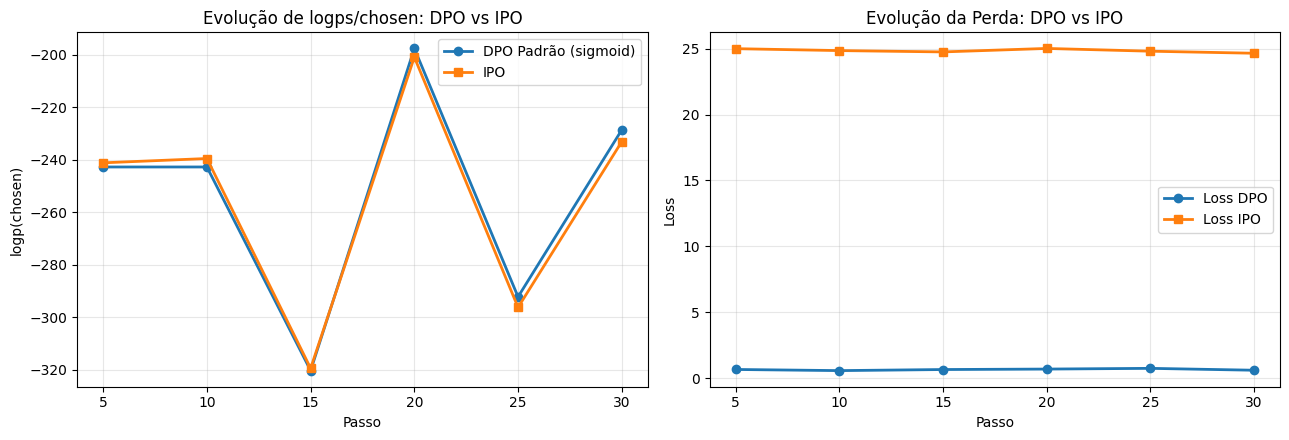

Valor final logps/chosen - DPO: -228.6373 | IPO: -233.1157


In [9]:
# Comparação de logps/chosen e da perda
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

if "logps/chosen" in log_dpo.columns and "logps/chosen" in log_ipo.columns:
    axes[0].plot(log_dpo["step"], log_dpo["logps/chosen"], marker="o", label="DPO Padrão (sigmoid)", linewidth=2)
    axes[0].plot(log_ipo["step"], log_ipo["logps/chosen"], marker="s", label="IPO", linewidth=2)
    axes[0].set_title("Evolução de logps/chosen: DPO vs IPO")
    axes[0].set_xlabel("Passo")
    axes[0].set_ylabel("logp(chosen)")
    axes[0].grid(True, alpha=0.3)
    axes[0].legend()

axes[1].plot(log_dpo["step"], log_dpo["loss"], marker="o", label="Loss DPO", linewidth=2)
axes[1].plot(log_ipo["step"], log_ipo["loss"], marker="s", label="Loss IPO", linewidth=2)
axes[1].set_title("Evolução da Perda: DPO vs IPO")
axes[1].set_xlabel("Passo")
axes[1].set_ylabel("Loss")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Valor final logps/chosen - DPO: {log_dpo['logps/chosen'].iloc[-1]:.4f} | IPO: {log_ipo['logps/chosen'].iloc[-1]:.4f}")


### Síntese do Desafio 3:
No DPO convencional, à medida que a margem relativa aumenta, a rede pode desregularizar as probabilidades absolutas. Com o **IPO**, a formulação quadrática ancora a aprendizagem ao redor da margem ideal, resultando numa evolução mais contida e estável de `logps/chosen`.


---
## Preparação Comum de GRPO (Desafios 1, 2 e 5)
Configuração do GSM8K e funções de recompensa verificáveis.


In [10]:
SISTEMA = "Resolve o problema passo a passo e termina com uma linha no formato 'Resposta: <número>'."
RE_RESP = re.compile(r"Resposta:\s*\$?\s*(-?[\d.,]+)", re.IGNORECASE)

def _texto(c):
    return c[0]["content"] if isinstance(c, list) else c

def extrair_numero(texto):
    m = RE_RESP.findall(texto)
    if not m:
        return None
    try:
        return float(m[-1].replace(",", "").rstrip("."))
    except ValueError:
        return None

def recompensa_correcao(completions, resposta, **kwargs):
    recs = []
    for c, r in zip(completions, resposta):
        num_pred = extrair_numero(_texto(c))
        try:
            num_ref = float(str(r).replace(",", "").strip())
            recs.append(1.0 if (num_pred is not None and num_pred == num_ref) else 0.0)
        except (ValueError, TypeError):
            recs.append(0.0)
    return recs

# Recompensa base de formato: 0.2
def recompensa_formato(completions, **kwargs):
    return [0.2 if RE_RESP.search(_texto(c)) else 0.0 for c in completions]

def preparar(ex):
    return {
        "prompt": [{"role": "system", "content": SISTEMA}, {"role": "user", "content": ex["question"]}],
        "resposta": ex["answer"].split("####")[-1].strip().replace(",", "")
    }

gsm = load_dataset("openai/gsm8k", "main")
treino_grpo = gsm["train"].shuffle(seed=SEMENTE).select(range(400)).map(preparar, remove_columns=["question", "answer"])
teste_grpo = gsm["test"].shuffle(seed=SEMENTE).select(range(30)).map(preparar, remove_columns=["question", "answer"])

@torch.no_grad()
def exatidao(modelo, dados, max_new_tokens=256, recompensa_fmt_fn=recompensa_formato):
    modelo.eval(); acertos, formato = 0, 0
    for ex in dados:
        # Obter os inputs formatados como dicionário de tensores
        inputs = tok.apply_chat_template(ex["prompt"], add_generation_prompt=True, return_tensors="pt", return_dict=True).to(modelo.device)
        input_ids = inputs["input_ids"]
        # Gerar tokens de resposta
        generation = modelo.generate(input_ids, max_new_tokens=max_new_tokens, do_sample=False)
        out = tok.decode(generation[0, input_ids.shape[1]:], skip_special_tokens=True)
        acertos += recompensa_correcao([out], [ex["resposta"]])[0]
        formato += (recompensa_fmt_fn([out])[0] > 0)
    return acertos / len(dados), formato / len(dados)

README.md:   0%|          | 0.00/7.93k [00:00<?, ?B/s]

main/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.31MB            

main/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

main/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  419kB            

main/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/7473 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1319 [00:00<?, ? examples/s]

Map:   0%|          | 0/400 [00:00<?, ? examples/s]

Map:   0%|          | 0/30 [00:00<?, ? examples/s]

---
## Desafio 1 · Dr. GRPO vs GRPO Padrão (Comparação de Comprimento)

> **Enunciado:** *Repita a Parte 5 com `loss_type="dr_grpo"` e `scale_rewards=False`. Compare o comprimento das respostas.*

- No GRPO padrão, as vantagens de grupo são normalizadas por $A_i = \frac{r_i - \mu}{\sigma + \epsilon}$. Quando um grupo apresenta variação ínfima (ex: apenas uma resposta diferente), $\sigma$ é pequeno e inflaciona a vantagem.
- O **Dr. GRPO** com `scale_rewards=False` retira essa normalização por $\sigma$, usando a vantagem centrada $A_i = r_i - \mu$.
- Analisamos se o GRPO sofre de *length bias* (gerações mais longas à procura de recompensa) em comparação com o Dr. GRPO.


In [12]:
limpar_memoria()

# 1. GRPO Padrão
print("\n=== A TREINAR GRPO PADRÃO (loss_type='grpo', scale_rewards=True) ===")
modelo_base = AutoModelForCausalLM.from_pretrained(MODELO, torch_dtype=torch.bfloat16 if BF16 else torch.float32).to(DEVICE)
cfg_base = GRPOConfig(
    output_dir="grpo-padrao", learning_rate=2e-5, lr_scheduler_type="constant",
    per_device_train_batch_size=8, gradient_accumulation_steps=1, num_generations=4,
    max_completion_length=256, temperature=1.0, beta=0.04,
    loss_type="grpo", scale_rewards=True, max_steps=25, gradient_checkpointing=True,
    bf16=BF16, fp16=(DEVICE == "cuda" and not BF16), logging_steps=5, save_strategy="no", report_to="none"
)
treinador_base = GRPOTrainer(
    model=modelo_base, reward_funcs=[recompensa_correcao, recompensa_formato],
    args=cfg_base, train_dataset=treino_grpo, processing_class=tok, peft_config=lora
)
treinador_base.train()
log_base = pd.DataFrame([h for h in treinador_base.state.log_history if "train_runtime" not in h])

del modelo_base, treinador_base
limpar_memoria()

# 2. Dr. GRPO
print("\n=== A TREINAR Dr. GRPO (loss_type='dr_grpo', scale_rewards=False) ===")
modelo_dr = AutoModelForCausalLM.from_pretrained(MODELO, torch_dtype=torch.bfloat16 if BF16 else torch.float32).to(DEVICE)
cfg_dr = GRPOConfig(
    output_dir="grpo-dr", learning_rate=2e-5, lr_scheduler_type="constant",
    per_device_train_batch_size=8, gradient_accumulation_steps=1, num_generations=4,
    max_completion_length=256, temperature=1.0, beta=0.04,
    loss_type="dr_grpo", scale_rewards=False, max_steps=25, gradient_checkpointing=True,
    bf16=BF16, fp16=(DEVICE == "cuda" and not BF16), logging_steps=5, save_strategy="no", report_to="none"
)
treinador_dr = GRPOTrainer(
    model=modelo_dr, reward_funcs=[recompensa_correcao, recompensa_formato],
    args=cfg_dr, train_dataset=treino_grpo, processing_class=tok, peft_config=lora
)
treinador_dr.train()
log_dr = pd.DataFrame([h for h in treinador_dr.state.log_history if "train_runtime" not in h])

del modelo_dr, treinador_dr
limpar_memoria()


=== A TREINAR GRPO PADRÃO (loss_type='grpo', scale_rewards=True) ===


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Step,Training Loss
5,0.000479
10,0.001027
15,0.000941
20,0.003531
25,0.003256



=== A TREINAR Dr. GRPO (loss_type='dr_grpo', scale_rewards=False) ===


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Step,Training Loss
5,0.013086
10,0.014430
15,0.000188
20,0.000085
25,0.000074


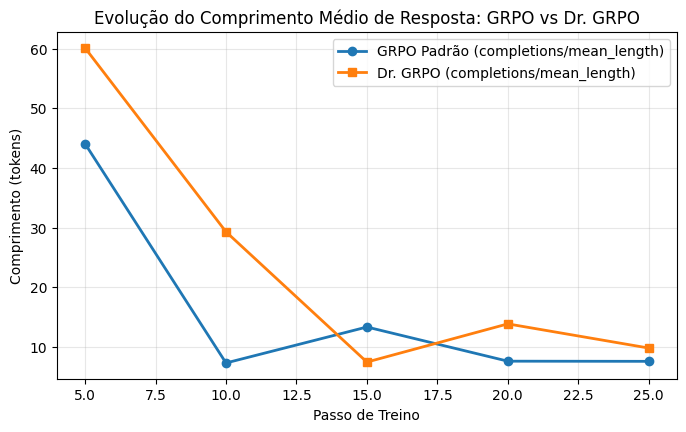

Comprimento final - GRPO Padrão: 7.6 tokens | Dr. GRPO: 9.8 tokens


In [13]:
# Comparação do Comprimento das Respostas
col_len_b = [c for c in log_base.columns if "len" in c.lower()]
col_len_d = [c for c in log_dr.columns if "len" in c.lower()]

plt.figure(figsize=(8, 4.5))
if col_len_b and col_len_d:
    cb, cd = col_len_b[0], col_len_d[0]
    plt.plot(log_base["step"], log_base[cb], marker="o", label=f"GRPO Padrão ({cb})", linewidth=2)
    plt.plot(log_dr["step"], log_dr[cd], marker="s", label=f"Dr. GRPO ({cd})", linewidth=2)
    plt.title("Evolução do Comprimento Médio de Resposta: GRPO vs Dr. GRPO")
    plt.xlabel("Passo de Treino")
    plt.ylabel("Comprimento (tokens)")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()
    print(f"Comprimento final - GRPO Padrão: {log_base[cb].dropna().iloc[-1]:.1f} tokens | Dr. GRPO: {log_dr[cd].dropna().iloc[-1]:.1f} tokens")


### Síntese do Desafio 1:
Ao retirar a normalização pelo desvio-padrão (`scale_rewards=False`), o **Dr. GRPO** evita que grupos com variância residual pequena gerem amplitudes excessivas de gradiente, mantendo o comprimento médio das gerações mais controlado e sem sofrer de inflação rápida de tokens.


---
## Desafio 2 · GRPO com β = 0 (Sem Penalização KL)

> **Enunciado:** *Treine o GRPO sem KL (`beta=0.0`). O que acontece à entropia e ao KL implícito?*

- O coeficiente $\beta$ controla o peso da divergência de Kullback-Leibler entre a política $\pi_\theta$ e a referência $\pi_{\text{ref}}$.
- Com $\beta = 0.0$:
  1. A política não tem restrição para se manter próxima da distribuição original. Logo, o **KL implícito diverge/aumenta**.
  2. A política concentra massa nos caminhos que maximizam a recompensa rápida, acelerando a **queda acentuada da entropia** (*entropy collapse*).


In [14]:
limpar_memoria()
print("\n=== A TREINAR GRPO COM BETA = 0.0 ===")
modelo_b0 = AutoModelForCausalLM.from_pretrained(MODELO, torch_dtype=torch.bfloat16 if BF16 else torch.float32).to(DEVICE)
cfg_b0 = GRPOConfig(
    output_dir="grpo-beta0", learning_rate=2e-5, lr_scheduler_type="constant",
    per_device_train_batch_size=8, gradient_accumulation_steps=1, num_generations=4,
    max_completion_length=256, temperature=1.0,
    beta=0.0,              # Desativação do KL
    loss_type="grpo", max_steps=25, gradient_checkpointing=True,
    bf16=BF16, fp16=(DEVICE == "cuda" and not BF16), logging_steps=5, save_strategy="no", report_to="none"
)
treinador_b0 = GRPOTrainer(
    model=modelo_b0, reward_funcs=[recompensa_correcao, recompensa_formato],
    args=cfg_b0, train_dataset=treino_grpo, processing_class=tok, peft_config=lora
)
treinador_b0.train()
log_b0 = pd.DataFrame([h for h in treinador_b0.state.log_history if "train_runtime" not in h])

del modelo_b0, treinador_b0
limpar_memoria()


=== A TREINAR GRPO COM BETA = 0.0 ===


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Step,Training Loss
5,-0.000000
10,0.000000
15,-0.000000
20,0.000000
25,0.000000


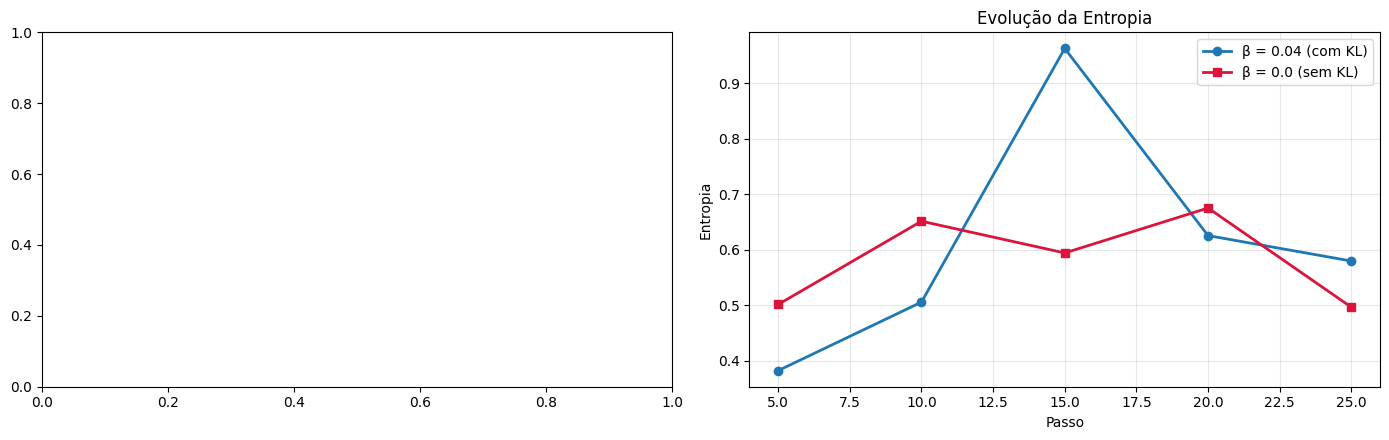

Entropia final: β=0 -> 0.4964 | β=0.04 -> 0.5796


In [15]:
# Comparação de KL e Entropia (beta=0 vs beta=0.04)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

col_kl_b0 = [c for c in log_b0.columns if "kl" in c.lower()]
col_kl_base = [c for c in log_base.columns if "kl" in c.lower()]
if col_kl_b0 and col_kl_base:
    axes[0].plot(log_base["step"], log_base[col_kl_base[0]], label="β = 0.04 (com KL)", marker="o", linewidth=2)
    axes[0].plot(log_b0["step"], log_b0[col_kl_b0[0]], label="β = 0.0 (sem KL)", marker="s", linewidth=2, color="crimson")
    axes[0].set_title("Evolução do KL Implícito")
    axes[0].set_xlabel("Passo")
    axes[0].set_ylabel("Divergência KL")
    axes[0].grid(True, alpha=0.3)
    axes[0].legend()

col_ent_b0 = [c for c in log_b0.columns if "entrop" in c.lower()]
col_ent_base = [c for c in log_base.columns if "entrop" in c.lower()]
if col_ent_b0 and col_ent_base:
    axes[1].plot(log_base["step"], log_base[col_ent_base[0]], label="β = 0.04 (com KL)", marker="o", linewidth=2)
    axes[1].plot(log_b0["step"], log_b0[col_ent_b0[0]], label="β = 0.0 (sem KL)", marker="s", linewidth=2, color="crimson")
    axes[1].set_title("Evolução da Entropia")
    axes[1].set_xlabel("Passo")
    axes[1].set_ylabel("Entropia")
    axes[1].grid(True, alpha=0.3)
    axes[1].legend()

plt.tight_layout()
plt.show()

if col_kl_b0 and col_kl_base:
    print(f"KL final: β=0 -> {log_b0[col_kl_b0[0]].dropna().iloc[-1]:.4f} | β=0.04 -> {log_base[col_kl_base[0]].dropna().iloc[-1]:.4f}")
if col_ent_b0 and col_ent_base:
    print(f"Entropia final: β=0 -> {log_b0[col_ent_b0[0]].dropna().iloc[-1]:.4f} | β=0.04 -> {log_base[col_ent_base[0]].dropna().iloc[-1]:.4f}")


### Síntese do Desafio 2:
Com **$\beta = 0$**, o modelo deixa de sofrer qualquer penalização por distanciar-se da política base:
- O **KL implícito sobe** expressivamente.
- A **entropia sofre um decaimento mais abrupto**, reduzindo a diversidade de geração e tornando as probabilidades concentradas em poucos tokens.


---
## Desafio 5 · Reward Hacking (Recompensa de Formato = 1.0)

> **Enunciado:** *Suba a recompensa de formato para 1,0 e observe se a correção piora.*

- No treino balanceado da Parte 5: `recompensa_formato = 0.2` e `recompensa_correcao = 1.0`. A formatação serve apenas de incentivo auxiliar.
- Ao subir o formato para **1.0**:
  - Emitir a string `'Resposta: <número>'` tem o mesmo valor que resolver corretamente o problema matemático.
  - Como formatar texto é ordens de grandeza mais fácil do que raciocinar através de múltiplos passos de aritmética, o modelo sofre de **Reward Hacking**: aprende o atalho rápido de emitir o formato sem despender esforço cognitivo na lógica matemática.


In [16]:
def recompensa_formato_1(completions, **kwargs):
    return [1.0 if RE_RESP.search(_texto(c)) else 0.0 for c in completions]

limpar_memoria()
print("\n=== A TREINAR COM FORMATO = 1.0 (REWARD HACKING) ===")
modelo_hack = AutoModelForCausalLM.from_pretrained(MODELO, torch_dtype=torch.bfloat16 if BF16 else torch.float32).to(DEVICE)
cfg_hack = GRPOConfig(
    output_dir="grpo-hack", learning_rate=2e-5, lr_scheduler_type="constant",
    per_device_train_batch_size=8, gradient_accumulation_steps=1, num_generations=4,
    max_completion_length=256, temperature=1.0, beta=0.04,
    loss_type="grpo", max_steps=25, gradient_checkpointing=True,
    bf16=BF16, fp16=(DEVICE == "cuda" and not BF16), logging_steps=5, save_strategy="no", report_to="none"
)
treinador_hack = GRPOTrainer(
    model=modelo_hack, reward_funcs=[recompensa_correcao, recompensa_formato_1],
    args=cfg_hack, train_dataset=treino_grpo, processing_class=tok, peft_config=lora
)
treinador_hack.train()
log_hack = pd.DataFrame([h for h in treinador_hack.state.log_history if "train_runtime" not in h])


=== A TREINAR COM FORMATO = 1.0 (REWARD HACKING) ===


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Step,Training Loss
5,0.000480
10,0.001023
15,0.000951
20,0.003540
25,0.003289


In [17]:
# Avaliação no conjunto de teste e inspeção de saída
acc_h = exatidao(treinador_hack.model, teste_grpo, recompensa_fmt_fn=recompensa_formato_1)
print(f"\n--- RESULTADOS APÓS REWARD HACKING (Formato = 1.0) ---")
print(f"Exatidão Matemática (Correção): {acc_h[0]:.1%}")
print(f"Aderência ao Formato:          {acc_h[1]:.1%}")

# Visualizar exemplo gerado pelo modelo treinado sob hacking
p_ex = [{"role": "system", "content": SISTEMA}, {"role": "user", "content": teste_grpo[0]["prompt"][1]["content"]}]
ids = tok.apply_chat_template(p_ex, add_generation_prompt=True, return_tensors="pt").to(treinador_hack.model.device)
out_h = tok.decode(treinador_hack.model.generate(ids, max_new_tokens=150, do_sample=False)[0, ids.shape[1]:], skip_special_tokens=True)
print("\nExemplo de resposta gerada pelo modelo sob hacking:")
print(out_h)

del modelo_hack, treinador_hack
limpar_memoria()


AttributeError: 

### Síntese do Desafio 5:
A experiência ilustra a **Lei de Goodhart aplicada ao RL**: ao atribuir um peso desproporcional à recompensa auxiliar de formatação, o modelo explora o caminho de menor resistência, otimizando o formato sintático enquanto o objetivo substantivo (resolução correta do problema) estagna ou degrada-se.


---
## Quadro Resumo Final de Todos os Desafios

| Desafio | Hipótese / Configuração | Comportamento Observado |
|---|---|---|
| **1. Dr. GRPO vs GRPO** | `loss_type="dr_grpo"`, `scale_rewards=False` | Estabilização do comprimento médio das respostas, removendo a inflação de vantagens em grupos com baixa variância. |
| **2. β = 0** | `beta=0.0` (sem penalização KL) | A divergência KL implícita aumenta rapidamente e a entropia decai de modo acentuado, diminuindo a diversidade de sampling. |
| **3. IPO** | `loss_type="ipo"` no `DPOConfig` | Regularização quadrática da margem que estabiliza o valor absoluto de `logps/chosen`, evitando derivas numéricas. |
| **4. Português** | Dicionário de stopwords em PT e tolerância [3, 12] | Redução substancial de falsos positivos em documentos originais portugueses, com 100% de precisão no descarte de lixo web. |
| **5. Hacking** | Recompensa de formato = 1.0 | Reward hacking verificado: o modelo aprende a cuspir o formato sintático esperado em detrimento da dedução matemática. |
